# Gaussian EM field recovery at the anchor

**A02.1 · Sprint 6 · Subteam A · Rishank Goyal**

This notebook evaluates where Gaussian EM recovers transformer fields well under scattered gaps. Gaussian EM is stronger than MissForest on location and installation day, while MissForest leads on mean numeric skill and on life and gas C.

**Run this notebook.** Use a Python 3 Jupyter kernel with pandas and Matplotlib, then run all cells. The tables and figures use embedded extracts of the saved benchmark scores. They reproduce the analysis from those scores.

## Scope and method

The anchor is mcar30-n05 with nominal 30% missing completely at random, ±5% measured noise, decay-corrected gas features enabled, and the model-only arm. It uses nine generator–split pairs with spatially blocked holdouts.

The model fits a Gaussian mixture with shared full covariance by incomplete-data expectation maximisation (EM). It conditions on the observed inputs, then combines the component estimates to predict missing numeric values. Within a component, the conditional mean is linear in the observed inputs. The mixture can express different patterns across components.

In [1]:
%matplotlib inline
from io import StringIO
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PAIR = ["generator_seed", "split_seed"]
FIELD = {
    "x": "x", "y": "y", "install_date": "Installation day", "model_id": "Model ID",
    "altitude": "Altitude", "measured_humid": "Humidity", "measured_salt": "Salt",
    "measured_overgrowth": "Overgrowth", "life": "Life", "random_placebo": "Placebo",
    "measured_gas_a": "Gas A", "measured_gas_b": "Gas B", "measured_gas_c": "Gas C",
    "total_gas": "Total gas", "leakage": "Leakage",
}
TEAL, NAVY, RUST, MUTE = "#087973", "#203e53", "#a3452a", "#647783"
plt.rcParams.update({
    "figure.dpi": 140, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY, "axes.axisbelow": True, "grid.alpha": 0.22,
})

In [2]:
CONDITIONS = ["30% scattered", "70% scattered", "30% grouped"]
NAMES = {"mixture": "Gaussian EM", "forest": "MissForest"}

In [3]:
# Archived score extract. Rows and columns are restricted to this analysis.
evidence = pd.read_csv(StringIO("""
method,generator_seed,split_seed,attribute,type,n,error,floor_error,skill,tolerance,macro_f1
forest,219,617,x,numeric,616,2.93806045580458,24.57792207792208,0.8804593632248598,0.7987012987012987,
forest,219,617,y,numeric,606,13.14311883018708,29.12376237623763,0.5487149407278957,0.3201320132013201,
forest,219,617,install_date,numeric,584,40.56736667299002,344.9332191780822,0.8823906645765948,0.6815068493150684,
forest,219,617,model_id,categorical,621,0.0402576489533011,0.7310789049919485,0.9449339207048458,0.9597423510466988,0.9582509905768252
forest,219,617,altitude,numeric,597,12.63008066926847,34.99832495812395,0.6391232813461627,0.371859296482412,
forest,219,617,measured_humid,numeric,618,0.0718844047525401,0.1741311408135003,0.5871823706161179,0.4692556634304207,
forest,219,617,measured_salt,numeric,575,0.139510710400903,0.2162327144193579,0.3548121949283844,0.3008695652173913,
forest,219,617,measured_overgrowth,numeric,616,0.09647228554927829,0.2972701719120389,0.6754727023946953,0.3198051948051948,
forest,219,617,life,numeric,585,90.70276005747355,274.5333408604432,0.6696111307530345,0.9897435897435898,
forest,219,617,random_placebo,numeric,622,0.2480647589891515,0.2477967902910142,-0.0010814050408907,0.1720257234726688,
forest,219,617,measured_gas_a,numeric,578,198.4332304805347,1220.294894538314,0.8373891168694844,0.9740484429065744,
forest,219,617,measured_gas_b,numeric,624,214.3855757913603,1059.373948919212,0.7976299341605678,0.966346153846154,
forest,219,617,measured_gas_c,numeric,627,193.2302609013663,980.7439168797237,0.8029758252122162,0.9696969696969696,
forest,219,617,total_gas,numeric,589,254.6399616435117,1156.240811604538,0.7797690938705556,0.99830220713073,
forest,219,617,leakage,numeric,609,0.0879515833896141,0.09998389750598689,0.1203425193106951,0.6075533661740559,
mixture,219,617,x,numeric,616,1.980097806982281,24.57792207792208,0.919435914854618,0.9155844155844156,
mixture,219,617,y,numeric,606,9.15850124469651,29.12376237623763,0.6855316587746567,0.693069306930693,
mixture,219,617,install_date,numeric,584,27.28576703991508,344.9332191780822,0.9208955081075332,0.7842465753424658,
mixture,219,617,model_id,categorical,621,0.0418679549114331,0.7310789049919485,0.9427312775330396,0.9581320450885668,0.956649700708758
mixture,219,617,altitude,numeric,597,8.838004005242036,34.99832495812395,0.7474735143519913,0.6800670016750419,
mixture,219,617,measured_humid,numeric,618,0.076290560685439,0.1741311408135003,0.5618787063070554,0.4401294498381877,
mixture,219,617,measured_salt,numeric,575,0.1500873424597116,0.2162327144193579,0.3058990039377905,0.2626086956521739,
mixture,219,617,measured_overgrowth,numeric,616,0.1035697483713957,0.2972701719120389,0.6515972399610896,0.3782467532467532,
mixture,219,617,life,numeric,585,136.041760667481,274.5333408604432,0.5044617887171789,0.9811965811965812,
mixture,219,617,random_placebo,numeric,622,0.2476488540128724,0.2477967902910142,0.0005970064340546,0.1623794212218649,
mixture,219,617,measured_gas_a,numeric,578,310.8950257323459,1220.294894538314,0.7452295939909102,0.9463667820069204,
mixture,219,617,measured_gas_b,numeric,624,233.9989653147818,1059.373948919212,0.7791158017869793,0.966346153846154,
mixture,219,617,measured_gas_c,numeric,627,343.0527083693892,980.7439168797237,0.6502117398180502,0.9665071770334928,
mixture,219,617,total_gas,numeric,589,275.6587637959782,1156.240811604538,0.7615905259273446,0.99660441426146,
mixture,219,617,leakage,numeric,609,0.08482031141818951,0.09998389750598689,0.1516602819657978,0.632183908045977,
forest,219,631,x,numeric,570,2.293685660912289,25.88245614035088,0.9113806800840504,0.8649122807017544,
forest,219,631,y,numeric,587,13.81183111967982,25.73253833049404,0.4632542292451469,0.3390119250425894,
forest,219,631,install_date,numeric,591,31.60770632289029,339.1006768189509,0.906789610037358,0.727580372250423,
forest,219,631,model_id,categorical,609,0.0394088669950738,0.7257799671592775,0.9457013574660632,0.9605911330049262,0.9576746418392404
forest,219,631,altitude,numeric,638,13.1223783380599,35.63949843260188,0.6318023845684664,0.3730407523510972,
forest,219,631,measured_humid,numeric,605,0.0754007817307159,0.1716513402382546,0.5607329274210238,0.4677685950413223,
forest,219,631,measured_salt,numeric,593,0.1269869896988256,0.2152094397975422,0.4099376411262982,0.342327150084317,
forest,219,631,measured_overgrowth,numeric,554,0.09806453380996211,0.2931362468524875,0.6654643195342869,0.3231046931407942,
forest,219,631,life,numeric,582,95.33864359699704,279.8650680217949,0.6593406805969353,0.9810996563573884,
forest,219,631,random_placebo,numeric,609,0.2486215056432443,0.2485204362599372,-0.0004066843951673,0.1724137931034483,
forest,219,631,measured_gas_a,numeric,594,221.2659484000851,1240.388415656093,0.8216155958832877,0.9646464646464646,
forest,219,631,measured_gas_b,numeric,596,217.5354964199993,1089.91145382662,0.800409936370295,0.964765100671141,
forest,219,631,measured_gas_c,numeric,627,171.4823623191263,990.0155742840516,0.8267882175054296,0.9840510366826156,
forest,219,631,total_gas,numeric,587,242.6462739961031,1102.674572162893,0.7799475202188139,1,
forest,219,631,leakage,numeric,572,0.08878669439022641,0.099290756221111,0.1057909339263476,0.5996503496503497,
mixture,219,631,x,numeric,570,2.29695124748228,25.88245614035088,0.9112545101969159,0.8982456140350877,
mixture,219,631,y,numeric,587,9.08867121786167,25.73253833049404,0.6468023829933929,0.676320272572402,
mixture,219,631,install_date,numeric,591,30.86621944871661,339.1006768189509,0.9089762375638184,0.7411167512690355,
mixture,219,631,model_id,categorical,609,0.0509031198686371,0.7257799671592775,0.9298642533936652,0.9490968801313628,0.9461157038255426
mixture,219,631,altitude,numeric,638,8.570086424582339,35.63949843260188,0.7595340338251592,0.6959247648902821,
mixture,219,631,measured_humid,numeric,605,0.0750258474712569,0.1716513402382546,0.5629172054985419,0.4413223140495868,
mixture,219,631,measured_salt,numeric,593,0.1433926356149744,0.2152094397975422,0.3337065709112449,0.2900505902192243,
mixture,219,631,measured_overgrowth,numeric,554,0.1038645887033351,0.2931362468524875,0.6456781110539291,0.4296028880866426,
mixture,219,631,life,numeric,582,139.5929601578407,279.8650680217949,0.5012133484734518,0.9810996563573884,
mixture,219,631,random_placebo,numeric,609,0.2482577179192119,0.2485204362599372,0.0010571297261464,0.1576354679802955,
mixture,219,631,measured_gas_a,numeric,594,321.2082404428822,1240.388415656093,0.7410422119486001,0.9528619528619529,
mixture,219,631,measured_gas_b,numeric,596,250.2477004690227,1089.91145382662,0.770396301836799,0.9546979865771812,
mixture,219,631,measured_gas_c,numeric,627,348.5893293520986,990.0155742840516,0.6478951054843884,0.9553429027113236,
mixture,219,631,total_gas,numeric,587,268.8946794878867,1102.674572162893,0.7561432118993634,1,
mixture,219,631,leakage,numeric,572,0.088250481826063,0.099290756221111,0.1111913617664711,0.6031468531468531,
forest,219,653,x,numeric,603,2.470461914949645,24.78441127694859,0.9003219448166855,0.8275290215588723,
forest,219,653,y,numeric,577,9.939601092169536,21.24783362218371,0.5322063760047453,0.3795493934142114,
forest,219,653,install_date,numeric,599,34.31742375950533,354.0025041736227,0.9030588107289936,0.7295492487479132,
forest,219,653,model_id,categorical,621,0.0354267310789049,0.71658615136876,0.950561797752809,0.964573268921095,0.9630076173826176
forest,219,653,altitude,numeric,593,11.14132440996698,29.52107925801012,0.6225976593676213,0.3136593591905565,
forest,219,653,measured_humid,numeric,617,0.06900462533092511,0.1827295049863342,0.6223673602350872,0.5040518638573744,
forest,219,653,measured_salt,numeric,585,0.1227582851950553,0.2090002966413376,0.412640617416352,0.3811965811965812,
forest,219,653,measured_overgrowth,numeric,564,0.08731023296785589,0.3263559278686487,0.7324692903908384,0.3953900709219858,
forest,219,653,life,numeric,567,92.4153888057257,288.3500521776141,0.6795027845224704,0.9788359788359788,
forest,219,653,random_placebo,numeric,602,0.2510213358614511,0.2493953506560511,-0.0065197093735815,0.154485049833887,
forest,219,653,measured_gas_a,numeric,592,189.4117666954088,1209.022164938691,0.8433347442352194,0.9746621621621622,
forest,219,653,measured_gas_b,numeric,615,191.6943752247785,1061.448423208742,0.819403024175881,0.9707317073170731,
forest,219,653,measured_gas_c,numeric,630,180.6111373112166,995.3032218080232,0.8185365692043812,0.9761904761904762,
forest,219,653,total_gas,numeric,606,252.8198806377704,1103.182309907934,0.7708267451652036,0.9933993399339934,
forest,219,653,leakage,numeric,612,0.08858137067292809,0.1015746857288105,0.1279188309828758,0.5980392156862745,
mixture,219,653,x,numeric,603,2.010463764318629,24.78441127694859,0.9188819237280608,0.913764510779436,
mixture,219,653,y,numeric,577,6.900777060102097,21.24783362218371,0.6752244401566958,0.7105719237435009,
mixture,219,653,install_date,numeric,599,27.06308515780012,354.0025041736227,0.9235511476932184,0.7813021702838063,
mixture,219,653,model_id,categorical,621,0.0402576489533011,0.71658615136876,0.9438202247191012,0.9597423510466988,0.9581458081547088
mixture,219,653,altitude,numeric,593,6.695234580742896,29.52107925801012,0.7732049522232071,0.7048903878583473,
mixture,219,653,measured_humid,numeric,617,0.0796270834789254,0.1827295049863342,0.5642352148610015,0.4457050243111831,
mixture,219,653,measured_salt,numeric,585,0.1342257489442527,0.2090002966413376,0.3577724476889352,0.3094017094017094,
mixture,219,653,measured_overgrowth,numeric,564,0.1037261631323146,0.3263559278686487,0.6821685948537076,0.4539007092198581,
mixture,219,653,life,numeric,567,153.0220289578809,288.3500521776141,0.4693185321026943,0.9753086419753086,
mixture,219,653,random_placebo,numeric,602,0.2495941516538265,0.2493953506560511,-0.000797131932301,0.1461794019933555,
mixture,219,653,measured_gas_a,numeric,592,315.5681846144982,1209.022164938691,0.7389889170224597,0.9459459459459461,
mixture,219,653,measured_gas_b,numeric,615,223.7749245700305,1061.448423208742,0.7891796533141362,0.9626016260162602,
mixture,219,653,measured_gas_c,numeric,630,331.4722974427521,995.3032218080232,0.6669635040057296,0.9714285714285714,
mixture,219,653,total_gas,numeric,606,263.6285678561844,1103.182309907934,0.7610290108094777,0.9983498349834984,
mixture,219,653,leakage,numeric,612,0.0870918996908005,0.1015746857288105,0.142582632021889,0.6045751633986928,
forest,220,617,x,numeric,584,3.449408298238765,24.84931506849315,0.8611869868955734,0.7945205479452054,
forest,220,617,y,numeric,586,14.7572854268267,29.23720136518771,0.4952565656849096,0.2559726962457337,
forest,220,617,install_date,numeric,599,47.86953856356736,336.652754590985,0.8578073759659971,0.6427378964941569,
forest,220,617,model_id,categorical,607,0.0345963756177924,0.71499176276771,0.9516129032258064,0.9654036243822076,0.9629533795591936
forest,220,617,altitude,numeric,609,12.81852040876022,34.8128078817734,0.6317872303695593,0.3316912972085385,
forest,220,617,measured_humid,numeric,578,0.0758880090849378,0.1802419403603323,0.5789658670272542,0.4532871972318339,
forest,220,617,measured_salt,numeric,584,0.146156408228597,0.207185875986769,0.2945638425761675,0.3030821917808219,
forest,220,617,measured_overgrowth,numeric,629,0.09201617715323469,0.299570842978257,0.6928400099341,0.3338632750397456,
forest,220,617,life,numeric,595,94.7047332420895,272.2572154989839,0.6521497765687574,0.9831932773109244,
forest,220,617,random_placebo,numeric,578,0.2386653815812861,0.2390283316174462,0.0015184393988113,0.1955017301038062,
forest,220,617,measured_gas_a,numeric,569,193.7020426610713,1227.054315280933,0.842140612482404,0.9736379613356766,
forest,220,617,measured_gas_b,numeric,595,210.09893784568,1066.815621340026,0.8030597474924721,0.9714285714285714,
forest,220,617,measured_gas_c,numeric,605,174.5315611702816,945.145029625917,0.8153388573186908,0.9851239669421488,
forest,220,617,total_gas,numeric,594,276.0790630378805,1068.509921895511,0.7416223683275464,1,
forest,220,617,leakage,numeric,600,0.0895476828634984,0.1011711155609459,0.1148888458232478,0.5833333333333334,
mixture,220,617,x,numeric,584,1.778086883498788,24.84931506849315,0.9284452356695636,0.9178082191780822,
mixture,220,617,y,numeric,586,9.620521320821096,29.23720136518771,0.6709493087024361,0.6604095563139932,
mixture,220,617,install_date,numeric,599,25.26122324340301,336.652754590985,0.9249635629029858,0.8013355592654424,
mixture,220,617,model_id,categorical,607,0.0395387149917627,0.71499176276771,0.9447004608294932,0.9604612850082372,0.9581207296163839
mixture,220,617,altitude,numeric,609,8.944702245194875,34.8128078817734,0.7430628900842564,0.6683087027914614,
mixture,220,617,measured_humid,numeric,578,0.077252919642714,0.1802419403603323,0.5713932091039793,0.4134948096885813,
mixture,220,617,measured_salt,numeric,584,0.1444921486517222,0.207185875986769,0.302596530948135,0.2773972602739726,
mixture,220,617,measured_overgrowth,numeric,629,0.0994036012856836,0.299570842978257,0.6681799860846326,0.4276629570747218,
mixture,220,617,life,numeric,595,144.6010954916145,272.2572154989839,0.4688805759414145,0.9747899159663864,
mixture,220,617,random_placebo,numeric,578,0.2391084873236229,0.2390283316174462,-0.0003353397717931,0.1782006920415225,
mixture,220,617,measured_gas_a,numeric,569,297.7269665163936,1227.054315280933,0.7573644762023193,0.9578207381370826,
mixture,220,617,measured_gas_b,numeric,595,234.8636253968588,1066.815621340026,0.779846094583948,0.9663865546218487,
mixture,220,617,measured_gas_c,numeric,605,322.8068225210419,945.145029625917,0.6584578954525032,0.968595041322314,
mixture,220,617,total_gas,numeric,594,261.5374963695896,1068.509921895511,0.7552315696744973,1,
mixture,220,617,leakage,numeric,600,0.0860166301056598,0.1011711155609459,0.1497906331393272,0.6333333333333333,
forest,220,631,x,numeric,594,2.765295332585744,24.72727272727273,0.888168203461606,0.8080808080808081,
forest,220,631,y,numeric,599,13.9482394674983,25.90317195325543,0.4615238823774502,0.348914858096828,
forest,220,631,install_date,numeric,600,37.90403513533909,339.5383333333334,0.8883659622074903,0.7033333333333334,
forest,220,631,model_id,categorical,585,0.0324786324786324,0.7247863247863248,0.9551886792452832,0.9675213675213676,0.9665610915608888
forest,220,631,altitude,numeric,606,14.92888006630024,33.37458745874587,0.5526872029578271,0.2937293729372937,
forest,220,631,measured_humid,numeric,599,0.07461983012445041,0.1679047180772127,0.5555822910816854,0.4557595993322204,
forest,220,631,measured_salt,numeric,620,0.1263935591204781,0.2075831468319625,0.391118397377447,0.3693548387096774,
forest,220,631,measured_overgrowth,numeric,580,0.0958875377138135,0.2919745681172522,0.6715894184478879,0.3241379310344827,
forest,220,631,life,numeric,618,92.97090191001068,284.7625250622748,0.6735142663534155,0.9789644012944984,
forest,220,631,random_placebo,numeric,614,0.2475397775797505,0.2472770483997421,-0.0010624891461159,0.1596091205211726,
forest,220,631,measured_gas_a,numeric,595,176.2143481902847,1218.715951786745,0.8554098287365985,0.9781512605042016,
forest,220,631,measured_gas_b,numeric,632,186.6830298586071,1054.611049991877,0.8229839997788331,0.9778481012658228,
forest,220,631,measured_gas_c,numeric,591,166.5063864135299,922.154156229811,0.8194375796187002,0.9813874788494078,
forest,220,631,total_gas,numeric,583,254.4185377215737,1023.645765097593,0.7514584181400703,0.9982847341337908,
forest,220,631,leakage,numeric,612,0.08756147794513899,0.0963134174457102,0.09086936932234251,0.5898692810457516,
mixture,220,631,x,numeric,594,2.356718899927387,24.72727272727273,0.9046915150764659,0.8838383838383839,
mixture,220,631,y,numeric,599,9.02292295702981,25.90317195325543,0.6516672562992488,0.7111853088480802,
mixture,220,631,install_date,numeric,600,32.10615788588259,339.5383333333334,0.9054417285651126,0.7,
mixture,220,631,model_id,categorical,585,0.2358974358974359,0.7247863247863248,0.6745283018867925,0.7641025641025641,0.6612206026580011
mixture,220,631,altitude,numeric,606,8.818350192977867,33.37458745874587,0.7357765034885246,0.7062706270627063,
mixture,220,631,measured_humid,numeric,599,0.08079390789608989,0.1679047180772127,0.5188109731440902,0.4140233722871452,
mixture,220,631,measured_salt,numeric,620,0.1454146625275082,0.2075831468319625,0.2994871464916147,0.2758064516129032,
mixture,220,631,measured_overgrowth,numeric,580,0.1075697238486281,0.2919745681172522,0.6315784469096982,0.3913793103448276,
mixture,220,631,life,numeric,618,133.6746797926701,284.7625250622748,0.5305748895033267,0.9789644012944984,
mixture,220,631,random_placebo,numeric,614,0.2477371153366896,0.2472770483997421,-0.0018605323054639,0.1596091205211726,
mixture,220,631,measured_gas_a,numeric,595,404.4881875783218,1218.715951786745,0.6681029841405568,0.9008403361344538,
mixture,220,631,measured_gas_b,numeric,632,232.3319657840137,1054.611049991877,0.7796989081559469,0.9620253164556962,
mixture,220,631,measured_gas_c,numeric,591,374.2391442097533,922.154156229811,0.5941685653298854,0.9543147208121828,
mixture,220,631,total_gas,numeric,583,263.5780039452454,1023.645765097593,0.7425105315410392,1,
mixture,220,631,leakage,numeric,612,0.08369878811865861,0.0963134174457102,0.1309747869154598,0.6290849673202614,
forest,220,653,x,numeric,569,3.020083134492516,25.20035149384886,0.8801571027598688,0.8084358523725835,
forest,220,653,y,numeric,626,10.4798946752306,21.19488817891374,0.5055461209907781,0.3578274760383386,
forest,220,653,install_date,numeric,573,41.93677589742045,344.5986038394415,0.8783025368351173,0.680628272251309,
forest,220,653,model_id,categorical,575,0.0382608695652173,0.7217391304347827,0.9469879518072289,0.9617391304347828,0.9611362902348924
forest,220,653,altitude,numeric,600,11.88324030267029,29.49,0.5970416987904277,0.305,
forest,220,653,measured_humid,numeric,584,0.07835423711702159,0.1728837013035385,0.5467806593320664,0.4434931506849315,
forest,220,653,measured_salt,numeric,608,0.1497683177045282,0.2142355952195552,0.300917676397141,0.3223684210526316,
forest,220,653,measured_overgrowth,numeric,581,0.101232705054425,0.3039601857515937,0.6669540624075161,0.3029259896729776,
forest,220,653,life,numeric,581,104.1594493274044,278.5106119664708,0.6260126370339388,0.982788296041308,
forest,220,653,random_placebo,numeric,605,0.2479521619836915,0.2488453048817261,0.0035891490838416,0.2016528925619834,
forest,220,653,measured_gas_a,numeric,573,192.1427044437931,1264.247047217481,0.8480180714151671,0.9685863874345548,
forest,220,653,measured_gas_b,numeric,619,184.1577249060518,1057.660710782905,0.8258820404043051,0.974151857835218,
forest,220,653,measured_gas_c,numeric,607,162.5819251284633,930.8848419507208,0.8253468981321429,0.9818780889621088,
forest,220,653,total_gas,numeric,622,242.6409287287455,1067.785898676155,0.7727625650146039,0.9983922829581994,
forest,220,653,leakage,numeric,550,0.0893445025495551,0.1034524527837668,0.1363713460105162,0.5745454545454546,
mixture,220,653,x,numeric,569,2.06928337632387,25.20035149384886,0.917886725634404,0.8945518453427065,
mixture,220,653,y,numeric,626,6.689880449944075,21.19488817891374,0.6843634939957046,0.7252396166134185,
mixture,220,653,install_date,numeric,573,28.79454971706859,344.5986038394415,0.9164403181085296,0.7574171029668412,
mixture,220,653,model_id,categorical,575,0.0365217391304347,0.7217391304347827,0.9493975903614458,0.9634782608695652,0.9609390983345988
mixture,220,653,altitude,numeric,600,6.692564138635475,29.49,0.7730564890255858,0.7083333333333334,
mixture,220,653,measured_humid,numeric,584,0.08024528653569871,0.1728837013035385,0.5358423846166442,0.4178082191780822,
mixture,220,653,measured_salt,numeric,608,0.1528066458814052,0.2142355952195552,0.2867354945157256,0.2927631578947368,
mixture,220,653,measured_overgrowth,numeric,581,0.1085671053354087,0.3039601857515937,0.6428245855062962,0.3975903614457831,
mixture,220,653,life,numeric,581,152.0334071424421,278.5106119664708,0.4541198769088735,0.9724612736660928,
mixture,220,653,random_placebo,numeric,605,0.2479416181872642,0.2488453048817261,0.0036315199713788,0.1867768595041322,
mixture,220,653,measured_gas_a,numeric,573,310.7078056734932,1264.247047217481,0.7542348970817536,0.9581151832460733,
mixture,220,653,measured_gas_b,numeric,619,220.595343468563,1057.660710782905,0.7914308991346827,0.9612277867528272,
mixture,220,653,measured_gas_c,numeric,607,317.8324449479543,930.8848419507208,0.6585695344636628,0.971993410214168,
mixture,220,653,total_gas,numeric,622,257.4535663542162,1067.785898676155,0.7588902731592466,1,
mixture,220,653,leakage,numeric,550,0.08791709643160441,0.1034524527837668,0.1501690480421363,0.5981818181818181,
forest,221,617,x,numeric,600,2.897512856593855,24.99833333333333,0.8840917585201471,0.805,
forest,221,617,y,numeric,583,12.91257950141891,28.38078902229845,0.545023942383221,0.3756432246998284,
forest,221,617,install_date,numeric,603,37.32487059977595,336.2504145936982,0.888996804227359,0.6915422885572139,
forest,221,617,model_id,categorical,586,0.0443686006825938,0.7235494880546075,0.9386792452830188,0.955631399317406,0.9549372231072232
forest,221,617,altitude,numeric,617,13.46514704075967,35.16045380875202,0.6170371658454541,0.3338735818476499,
forest,221,617,measured_humid,numeric,610,0.07194791346378859,0.1713619112442683,0.5801405753392288,0.4590163934426229,
forest,221,617,measured_salt,numeric,597,0.1274676965986425,0.2053399690429569,0.3792358244099257,0.3668341708542713,
forest,221,617,measured_overgrowth,numeric,618,0.0931642220450712,0.2988041379067749,0.6882097326438703,0.3915857605177993,
forest,221,617,life,numeric,591,83.87453347519764,287.4906744309658,0.7082530289331588,0.9898477157360406,
forest,221,617,random_placebo,numeric,586,0.256704730560453,0.2516600328961282,-0.0200456846733663,0.1501706484641638,
forest,221,617,measured_gas_a,numeric,620,209.8607331984527,1273.119651315581,0.835160243594078,0.9693548387096774,
forest,221,617,measured_gas_b,numeric,614,204.9310730213661,1092.573134712435,0.8124326266952338,0.970684039087948,
forest,221,617,measured_gas_c,numeric,574,182.9753856756472,950.4269253612144,0.8074808480345751,0.9738675958188152,
forest,221,617,total_gas,numeric,580,258.6416036731848,1064.668130437448,0.7570683330523711,0.996551724137931,
forest,221,617,leakage,numeric,642,0.0864676162961009,0.0984679006585243,0.1218700132953883,0.616822429906542,
mixture,221,617,x,numeric,600,1.877882445109299,24.99833333333333,0.9248796941752396,0.9116666666666666,
mixture,221,617,y,numeric,583,9.880926016970738,28.38078902229845,0.6518445625592928,0.6689536878216124,
mixture,221,617,install_date,numeric,603,26.06855928064159,336.2504145936982,0.9224727817446976,0.8142620232172471,
mixture,221,617,model_id,categorical,586,0.0358361774744027,0.7235494880546075,0.9504716981132076,0.9641638225255972,0.9635636064539556
mixture,221,617,altitude,numeric,617,8.93900895155193,35.16045380875202,0.745765256609775,0.6888168557536467,
mixture,221,617,measured_humid,numeric,610,0.0780635779359193,0.1713619112442683,0.5444519883730561,0.4327868852459016,
mixture,221,617,measured_salt,numeric,597,0.1406949143266437,0.2053399690429569,0.3148196379770055,0.2864321608040201,
mixture,221,617,measured_overgrowth,numeric,618,0.1041170906800552,0.2988041379067749,0.6515540534029045,0.4174757281553398,
mixture,221,617,life,numeric,591,136.7331880454616,287.4906744309658,0.5243908752306508,0.976311336717428,
mixture,221,617,random_placebo,numeric,586,0.2524929948905586,0.2516600328961282,-0.0033098700053586,0.167235494880546,
mixture,221,617,measured_gas_a,numeric,620,303.302654736967,1273.119651315581,0.7617642187648674,0.9548387096774194,
mixture,221,617,measured_gas_b,numeric,614,213.5704647444128,1092.573134712435,0.8045252459913135,0.972312703583062,
mixture,221,617,measured_gas_c,numeric,574,332.0929470796308,950.4269253612144,0.6505855019275497,0.9790940766550522,
mixture,221,617,total_gas,numeric,580,263.7438631146148,1064.668130437448,0.7522759857513078,0.9982758620689656,
mixture,221,617,leakage,numeric,642,0.08336138476367511,0.0984679006585243,0.1534156389424494,0.6433021806853583,
forest,221,631,x,numeric,570,2.776813827662744,24.35789473684211,0.8859994323128951,0.8350877192982457,
forest,221,631,y,numeric,632,13.68733708982037,25.57594936708861,0.4648356198486467,0.3196202531645569,
forest,221,631,install_date,numeric,637,35.08892774365601,343.3971742543171,0.8978182397107629,0.7111459968602826,
forest,221,631,model_id,categorical,590,0.0389830508474576,0.6813559322033899,0.9427860696517412,0.9610169491525424,0.9574686843672836
forest,221,631,altitude,numeric,613,13.80978079528745,33.95269168026101,0.5932640355781864,0.298531810766721,
forest,221,631,measured_humid,numeric,589,0.06780600408707591,0.1745855587464715,0.6116173378031682,0.4448217317487266,
forest,221,631,measured_salt,numeric,608,0.1340556574191197,0.1988111276556108,0.3257135101042397,0.3733552631578947,
forest,221,631,measured_overgrowth,numeric,598,0.0928267699769173,0.2831033582396404,0.6721099652292305,0.3160535117056856,
forest,221,631,life,numeric,579,96.76709444222068,285.8070694871114,0.661425119344067,0.9810017271157168,
forest,221,631,random_placebo,numeric,631,0.2449336383678906,0.2440457912590222,-0.003638034912579,0.1759112519809825,
forest,221,631,measured_gas_a,numeric,590,198.1114553615871,1273.565946889698,0.8444435045979246,0.9745762711864406,
forest,221,631,measured_gas_b,numeric,600,196.1672981785284,1065.032377058519,0.8158109533530644,0.9783333333333334,
forest,221,631,measured_gas_c,numeric,592,176.2055025346098,929.743034416504,0.8104793518080031,0.983108108108108,
forest,221,631,total_gas,numeric,597,248.1901356944955,1135.697834776518,0.7814646395417897,0.9983249581239531,
forest,221,631,leakage,numeric,601,0.0841278172747066,0.0978784504363145,0.140486829330782,0.627287853577371,
mixture,221,631,x,numeric,570,2.153243792507186,24.35789473684211,0.9115997578702754,0.8964912280701754,
mixture,221,631,y,numeric,632,9.212400907303504,25.57594936708861,0.6398021916966212,0.7009493670886076,
mixture,221,631,install_date,numeric,637,28.70450119970888,343.3971742543171,0.916410199757641,0.7488226059654631,
mixture,221,631,model_id,categorical,590,0.0305084745762711,0.6813559322033899,0.9552238805970148,0.9694915254237289,0.9667989724198192
mixture,221,631,altitude,numeric,613,9.40002953598434,33.95269168026101,0.7231433188123577,0.6867862969004894,
mixture,221,631,measured_humid,numeric,589,0.0735794226338492,0.1745855587464715,0.5785480588305743,0.4142614601018676,
mixture,221,631,measured_salt,numeric,608,0.1438068486503842,0.1988111276556108,0.2766659977931786,0.3026315789473684,
mixture,221,631,measured_overgrowth,numeric,598,0.1061414366869591,0.2831033582396404,0.6250788498343671,0.3963210702341137,
mixture,221,631,life,numeric,579,136.3320423427253,285.8070694871114,0.5229927566614188,0.9792746113989638,
mixture,221,631,random_placebo,numeric,631,0.2445230779961475,0.2440457912590222,-0.0019557261555833,0.1695721077654516,
mixture,221,631,measured_gas_a,numeric,590,284.6199324763692,1273.565946889698,0.7765173188153563,0.9677966101694916,
mixture,221,631,measured_gas_b,numeric,600,220.8516542380902,1065.032377058519,0.7926338588428141,0.9733333333333334,
mixture,221,631,measured_gas_c,numeric,592,330.5285405922144,929.743034416504,0.6444947384847574,0.9712837837837838,
mixture,221,631,total_gas,numeric,597,262.2463557371909,1135.697834776518,0.7690879143141137,1,
mixture,221,631,leakage,numeric,601,0.0846382281915728,0.0978784504363145,0.1352720868150296,0.6306156405990017,
forest,221,653,x,numeric,584,2.854172222878344,24.11815068493151,0.881658744894501,0.8184931506849316,
forest,221,653,y,numeric,619,10.58208245611124,21.12600969305331,0.4990969610512457,0.332794830371567,
forest,221,653,install_date,numeric,617,36.70893246263707,347.7811993517018,0.894448197513074,0.6855753646677472,
forest,221,653,model_id,categorical,583,0.0325900514579759,0.7135506003430532,0.9543269230769232,0.967409948542024,0.966579398028359
forest,221,653,altitude,numeric,585,11.81504047615186,28.4017094017094,0.5840024869967598,0.3042735042735042,
forest,221,653,measured_humid,numeric,599,0.0738532525664758,0.168862766240481,0.5626433570246039,0.4507512520868113,
forest,221,653,measured_salt,numeric,590,0.1461759920293118,0.2149743264750568,0.3200304686323908,0.2745762711864407,
forest,221,653,measured_overgrowth,numeric,586,0.1050176327679048,0.3110373992684573,0.6623633266774336,0.2832764505119454,
forest,221,653,life,numeric,598,92.19685964275668,319.255608067339,0.7112130302083525,0.9866220735785952,
forest,221,653,random_placebo,numeric,587,0.2539269837610104,0.2498292128791878,-0.0164022887259553,0.1635434412265758,
forest,221,653,measured_gas_a,numeric,570,182.4226999895599,1254.040807848105,0.8545320863181545,0.9771929824561404,
forest,221,653,measured_gas_b,numeric,559,179.9641469398614,1067.402903212183,0.8313999836441448,0.9785330948121646,
forest,221,653,measured_gas_c,numeric,591,193.083292760998,960.4717393202434,0.7989703550281977,0.9746192893401016,
forest,221,653,total_gas,numeric,602,245.0361222938442,1045.162597849416,0.7655521516001014,0.9950166112956812,
forest,221,653,leakage,numeric,587,0.0873957287789819,0.09836024631508219,0.1114730589528737,0.6013628620102215,
mixture,221,653,x,numeric,584,1.961532477625739,24.11815068493151,0.9186698639024896,0.9246575342465754,
mixture,221,653,y,numeric,619,7.139005893610086,21.12600969305331,0.662075044112209,0.7075928917609047,
mixture,221,653,install_date,numeric,617,26.34369496162128,347.7811993517018,0.9242521015778642,0.8184764991896273,
mixture,221,653,model_id,categorical,583,0.0325900514579759,0.7135506003430532,0.9543269230769232,0.967409948542024,0.9670718024735389
mixture,221,653,altitude,numeric,585,7.263020683211345,28.4017094017094,0.7442752272236752,0.6820512820512821,
mixture,221,653,measured_humid,numeric,599,0.07437456595743849,0.168862766240481,0.5595561554906654,0.4457429048414023,
mixture,221,653,measured_salt,numeric,590,0.1462877895935752,0.2149743264750568,0.319510417861229,0.2813559322033898,
mixture,221,653,measured_overgrowth,numeric,586,0.1130582090480832,0.3110373992684573,0.636512492343397,0.3907849829351535,
mixture,221,653,life,numeric,598,155.413454801033,319.255608067339,0.5132005487958335,0.9732441471571908,
mixture,221,653,random_placebo,numeric,587,0.2513726618990082,0.2498292128791878,-0.0061780165819387,0.1584327086882453,
mixture,221,653,measured_gas_a,numeric,570,281.3928425880417,1254.040807848105,0.7756110958853857,0.968421052631579,
mixture,221,653,measured_gas_b,numeric,559,223.7073483059957,1067.402903212183,0.7904190183174664,0.966010733452594,
mixture,221,653,measured_gas_c,numeric,591,361.4375421215328,960.4717393202434,0.6236874784287419,0.9560067681895094,
mixture,221,653,total_gas,numeric,602,268.7901431059107,1045.162597849416,0.7428245675275904,0.9983388704318936,
mixture,221,653,leakage,numeric,587,0.08529300670770019,0.09836024631508219,0.1328508223283934,0.6337308347529813,
"""))

In [4]:
def pooled_fields(rows, keys):
    """Sum errors and tolerance counts before calculating each field score."""
    weighted = rows.assign(
        absolute_error=rows.error * rows.n,
        floor_absolute_error=rows.floor_error * rows.n,
        within_n=(rows.tolerance * rows.n).round().astype(int),
    )
    totals = weighted.groupby(keys)[["n", "absolute_error", "floor_absolute_error", "within_n"]].sum()
    totals["Skill"] = 1 - totals.absolute_error / totals.floor_absolute_error
    totals["Within loose"] = totals.within_n / totals.n
    totals["Breaks"] = totals.Skill.lt(0.10) | totals["Within loose"].lt(0.50)
    totals["Below floor"] = totals.Skill.lt(0)
    return totals

## Pair averages and field results

Numeric skill is 1 − MAE / median-floor MAE. The headline averages 13 numeric fields equally within each pair, then averages the nine pairs. The placebo and Model ID are separate checks. For field breaks, errors and loose-tolerance counts are pooled by target across pairs before applying the thresholds.

In [5]:
keys = ["method", *PAIR]
assert evidence.groupby(["method", "attribute"]).size().eq(9).all()
targets = evidence.loc[evidence.type.eq("numeric") & evidence.attribute.ne("random_placebo")]
assert targets.attribute.nunique() == 13
mean_skill = targets.groupby(keys).skill.mean().groupby(level="method").mean()
assert round(mean_skill["mixture"], 3) == 0.641
assert round(mean_skill["forest"], 3) == 0.656

pooled = pooled_fields(targets, ["method", "attribute"])
breaks = pooled.groupby(level="method").Breaks.sum()
assert breaks.to_dict() == {"forest": 5, "mixture": 3}
overview = pd.DataFrame({"Mean numeric skill": mean_skill, "Fields that break": breaks})
display(overview.rename(index=NAMES).style.format({"Mean numeric skill": "{:.3f}"}))

numeric = evidence.loc[evidence.type.eq("numeric")]
field_skill = numeric.groupby(["attribute", "method"]).skill.mean().unstack("method")
field_skill = field_skill.rename(columns=NAMES).rename(index=FIELD).sort_values("Gaussian EM", ascending=False)
loose = pooled.xs("mixture")["Within loose"].rename(index=FIELD)
field_table = field_skill.join(loose.rename("EM within loose, pooled"))
display(field_table.style.format({
    "Gaussian EM": "{:.3f}", "MissForest": "{:.3f}", "EM within loose, pooled": "{:.1%}",
}, na_rep="—"))

categories = evidence.loc[evidence.attribute.eq("model_id")].groupby("method")[["skill", "macro_f1"]].mean()
display(categories.rename(index=NAMES, columns={"skill": "Model ID skill", "macro_f1": "Model ID macro F1"})
        .style.format(precision=3))

,Mean numeric skill,Fields that break
method,,
MissForest,0.656,5
Gaussian EM,0.641,3


,MissForest,Gaussian EM,"EM within loose, pooled"
attribute,,,
Installation day,0.889,0.918,77.2%
x,0.886,0.917,90.6%
Gas B,0.814,0.786,96.5%
Total gas,0.767,0.756,99.9%
Altitude,0.608,0.749,69.1%
Gas A,0.842,0.747,95.0%
y,0.502,0.663,69.5%
Overgrowth,0.681,0.648,40.9%
Gas C,0.814,0.644,96.6%


,Model ID skill,Model ID macro F1
method,,
MissForest,0.948,0.961
Gaussian EM,0.916,0.927


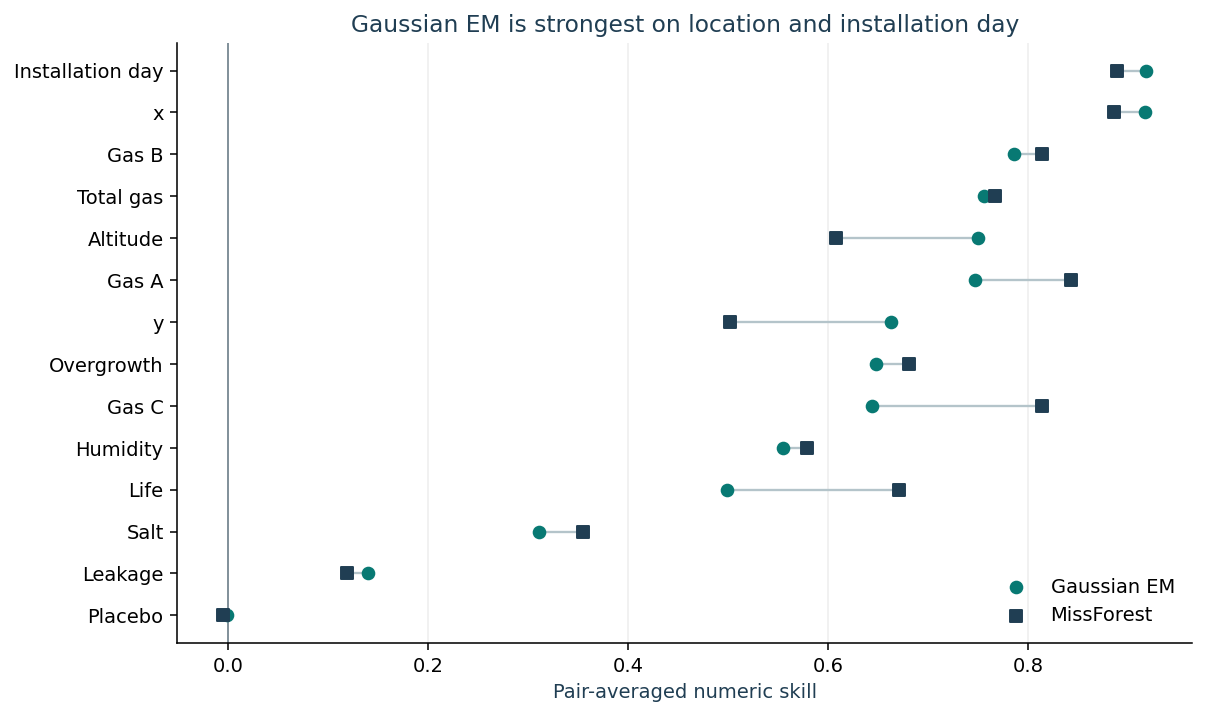

In [6]:
chart = field_skill.iloc[::-1]
y = range(len(chart))
fig, ax = plt.subplots(figsize=(8.5, 5), layout="constrained")
ax.hlines(y, chart["Gaussian EM"], chart["MissForest"], color="#b4c4ca", linewidth=1.2)
ax.scatter(chart["Gaussian EM"], y, label="Gaussian EM", color=TEAL, zorder=3)
ax.scatter(chart["MissForest"], y, label="MissForest", color=NAVY, marker="s", zorder=3)
ax.axvline(0, color=MUTE, linewidth=0.8)
ax.set(yticks=list(y), yticklabels=chart.index, xlabel="Pair-averaged numeric skill",
       title="Gaussian EM is strongest on location and installation day")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x")
plt.show()

## Interpretation

Gaussian EM reaches about 0.92 for x and installation day, 0.66 for y, and 0.75 for altitude. Its life and gas C skills are about 0.50 and 0.64, compared with 0.67 and 0.81 for MissForest. The results are consistent with a model that captures conditional location and date structure more readily than some nonlinear targets.

Although MissForest has the higher mean skill, Gaussian EM clears the break rule on two more fields. Its three anchor breaks are humidity, salt, and overgrowth. All three improve on the median by more than 0.10 skill but fall short of the loose tolerance rule, which requires at least half of fills to be within tolerance.

## Sources and reproducibility

Paths are relative to the original Subteam A run archive. Hash prefixes identify the archived files. The embedded extracts allow the calculations above to run in a fresh notebook session. Use the repository’s setup and benchmark instructions to reproduce the source runs with the Team 19 data.

| Archived source | Evidence used | SHA-256 prefix |
| --- | --- | --- |
| final/tables/cells.csv | Gaussian EM and MissForest anchor rows, model only, gas features on, group all | 9d8119486d0cbae0 |

[Sections 6 and 8A of the capstone report](https://github.com/alienblack/SAPN_endtoend/blob/6ae6621/docs/Final_Report.pdf) · [Source code and reproduction guide](https://github.com/alienblack/SAPN_endtoend)